# 01 · EDA de la equidad: desigualdad social y de recursos

Mide cuánta desigualdad hay en cada país y edición PISA, de dos tipos, y cómo se relaciona con el rendimiento en matemáticas:

* **Desigualdad social**: del conjunto de los hogares (Gini), de los alumnos (dispersión del `ESCS`) y entre centros (segregación).
* **Desigualdad de recursos entre centros**: cuánto mejor o peor dotados están los centros desfavorecidos que los favorecidos.

Los datos salen de las tablas maestras de `00_pipeline_multiedicion_PISA.ipynb` y, para el Gini, de la OCDE y el Banco Mundial. El presupuesto por alumno se analiza en `01_EDA_presupuestos.ipynb`.

| Variable | Qué mide | Nivel y fuente |
|---|---|---|
| `gini` | Desigualdad de la renta disponible de los hogares (0 = todos igual, 1 = uno concentra todo) | País y edición; OCDE (base de distribución de ingresos) y Banco Mundial |
| `pisa_escs_trend_desviacion_tipica` | Desviación típica de `ESCS_TREND` entre los alumnos del país | Alumnos; tablas maestras |
| `pisa_segregacion_social_entre_centros_pct` | % de la varianza de `ESCS_TREND` que es **entre centros** (más alto = centros más separados por nivel socioeconómico) | Alumnos y centros; tablas maestras |
| `pisa_brecha_alumnos_por_profesor`, `pisa_brecha_tamaño_clase`, `pisa_brecha_profesorado_certificado`, `pisa_brecha_escasez_material` y `pisa_brecha_escasez_personal` | **Brecha de recursos**: media del cuartil de centros más desfavorecido (por `ESCS_TREND` medio del centro) menos la del más favorecido, en alumnos por profesor, tamaño de clase, profesorado certificado, escasez de material y escasez de personal | Centros; tablas maestras (peso `W_SCHGRNRABWT`) |

## 0. Configuración

In [1]:
import sys, os
sys.path.append(os.path.abspath('../../'))   # para importar `src`

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.datos_externos import descargar_todo, cargar_oecd
from src.presupuesto_pais_edicion import construir_tabla

RUTA_RAW = '../../data/raw'                    # tablas maestras: data/raw/datos_anuales/
RUTA_EXTERNOS = '../../data/raw/externos'
RUTA_INTERMEDIOS = '../../data/intermediate'
RUTA_REPORTS = '../../reports'
EDICIONES = [2012, 2015, 2018, 2022]


if not os.path.isdir(os.path.join(RUTA_RAW, 'datos_anuales')):
    raise FileNotFoundError('Faltan las tablas maestras en data/raw/datos_anuales: se generan con 00_pipeline_multiedicion_PISA.ipynb')

rutas = descargar_todo(RUTA_EXTERNOS)      # descarga lo que falte (salta los ficheros que ya existen)
tabla_pais_edicion = construir_tabla(RUTA_RAW, RUTA_EXTERNOS)

SOCIAL = ['gini', 'pisa_escs_trend_desviacion_tipica', 'pisa_segregacion_social_entre_centros_pct']
RECURSOS = ['pisa_brecha_alumnos_por_profesor', 'pisa_brecha_tamaño_clase', 'pisa_brecha_profesorado_certificado', 'pisa_brecha_escasez_material', 'pisa_brecha_escasez_personal']
print(f'{tabla_pais_edicion.shape[0]} filas (33 países × 4 ediciones)')

132 filas (33 países × 4 ediciones)


## 1. Gini

El **Gini** mide la desigualdad de la renta con un número de 0 (todos los hogares ingresan lo mismo) a 1 (uno solo concentra todo). Se usa el de la **renta disponible de los hogares** (después de impuestos y transferencias) de la OCDE, para la población total, con la metodología desde 2012 y la definición actual.

Para cada país y edición se toma la **observación más cercana al año de la edición (como mucho ±1 año)**. A igual distancia se prefiere la de la OCDE a la del Banco Mundial (que va de 0 a 100 y se divide entre 100) y, si aún empatan, el año anterior. `gini_fuente` y `gini_año` indican qué observación se usó. Las fuentes y sus enlaces están en `01_EDA_presupuestos.ipynb` (sección "Fuentes"); el Gini se guarda también en `presupuesto_pais_edicion.parquet`.

In [2]:
# Gini usado en cada edición: de qué fuente y de qué año es la observación
distancia_gini = (tabla_pais_edicion['gini_año'] - tabla_pais_edicion['edicion']).abs()
gini_cobertura = pd.DataFrame({
    'países con Gini': tabla_pais_edicion.groupby('edicion')['gini'].count(),
    'de la OCDE': tabla_pais_edicion[tabla_pais_edicion['gini_fuente'] == 'OCDE'].groupby('edicion').size(),
    'del Banco Mundial': tabla_pais_edicion[tabla_pais_edicion['gini_fuente'] == 'Banco Mundial'].groupby('edicion').size(),
    'del año exacto': tabla_pais_edicion[distancia_gini == 0].groupby('edicion').size(),
    'a ±1 año': tabla_pais_edicion[distancia_gini == 1].groupby('edicion').size(),
}).fillna(0).astype(int)
gini_cobertura['sin dato'] = [', '.join(sorted(tabla_pais_edicion[(tabla_pais_edicion['edicion'] == edicion_pisa) & tabla_pais_edicion['gini'].isna()]['pais'])) or '-' for edicion_pisa in gini_cobertura.index]
gini_cobertura

,países con Gini,de la OCDE,del Banco Mundial,del año exacto,a ±1 año,sin dato
edicion,,,,,,
2012,33,26,7,32,1,-
2015,33,29,4,31,2,-
2018,33,31,2,31,2,-
2022,31,30,1,29,2,"AUS, ISL"


In [3]:
# ¿Coinciden las dos fuentes? Países y años con dato en ambas
gini_ocde = cargar_oecd(rutas['gini_ocde']).assign(año=lambda datos: datos['año'].astype(int))
gini_banco_mundial = pd.read_csv(rutas['gini_banco_mundial']).dropna().assign(valor=lambda datos: datos['valor'] / 100)
ambas = gini_ocde.merge(gini_banco_mundial, on=['pais', 'año'], suffixes=('_ocde', '_bm'))
diferencia = ambas['valor_bm'] - ambas['valor_ocde']
print(f'{len(ambas)} pares país-año con dato en las dos fuentes: correlación = {ambas[["valor_ocde", "valor_bm"]].corr().iloc[0, 1]:.2f}; '
      f'el Banco Mundial es de media {diferencia.mean():+.3f} mayor (|diferencia| mediana {diferencia.abs().median():.3f}, percentil 90 {diferencia.abs().quantile(.9):.3f})')

444 pares país-año con dato en las dos fuentes: correlación = 0.96; el Banco Mundial es de media +0.013 mayor (|diferencia| mediana 0.017, percentil 90 0.028)


Las dos fuentes están muy correlacionadas, pero el Banco Mundial da valores algo más altos (las definiciones de renta y las encuestas de cada fuente no son idénticas). Por eso se prefiere siempre la OCDE y el Banco Mundial solo rellena huecos.

## 2. Cobertura

% de países sin dato en cada edición (de 33). Las brechas de recursos dependen de preguntas de centro que no existen en todas las ediciones.

In [4]:
porcentaje_nulos = tabla_pais_edicion.groupby('edicion')[SOCIAL + RECURSOS].agg(lambda columna: 100 * columna.isna().mean()).T
porcentaje_nulos['total'] = 100 * tabla_pais_edicion[SOCIAL + RECURSOS].isna().mean()
porcentaje_nulos.sort_values('total', ascending=False).round(0).astype(int)

edicion,2012,2015,2018,2022,total
pisa_brecha_escasez_personal,100,0,0,18,30
pisa_brecha_escasez_material,100,0,0,0,25
pisa_brecha_profesorado_certificado,6,6,9,12,8
pisa_brecha_alumnos_por_profesor,0,0,9,6,4
pisa_brecha_tamaño_clase,0,0,6,6,3
gini,0,0,0,6,2
pisa_segregacion_social_entre_centros_pct,0,0,0,0,0
pisa_escs_trend_desviacion_tipica,0,0,0,0,0


## 3. Desigualdad social y rendimiento

Relación de las tres medidas de desigualdad social con la nota media de matemáticas.

In [5]:
vars_equidad = SOCIAL + RECURSOS
datos_estandarizados = tabla_pais_edicion[['pais', 'edicion', 'pisa_matematicas'] + vars_equidad].copy()
datos_estandarizados[['pisa_matematicas'] + vars_equidad] = datos_estandarizados.groupby('edicion')[['pisa_matematicas'] + vars_equidad].transform(lambda columna: (columna - columna.mean()) / columna.std(ddof=0))

nombres_variables = {'gini': 'Gini de la renta', 'pisa_escs_trend_desviacion_tipica': 'dispersión del ESCS dentro del país', 'pisa_segregacion_social_entre_centros_pct': 'segregación social entre centros'}
colores = {2012: 'tab:blue', 2015: 'tab:orange', 2018: 'tab:green', 2022: 'tab:red'}
fig, ejes = plt.subplots(1, 3, figsize=(15, 4.4), sharey=True)
for ax, variable in zip(ejes, SOCIAL):
    datos_variable = datos_estandarizados[['pais', 'edicion', 'pisa_matematicas', variable]].dropna()
    ax.scatter(datos_variable[variable], datos_variable['pisa_matematicas'], c=datos_variable['edicion'].map(colores), s=20, alpha=0.75)
    for _, fila_espana in datos_variable[datos_variable['pais'] == 'ESP'].iterrows():
        ax.annotate(f"ESP {int(fila_espana['edicion']) % 100}", (fila_espana[variable], fila_espana['pisa_matematicas']), fontsize=7, xytext=(3, 3), textcoords='offset points')
    ax.set_title(f'{nombres_variables[variable]}\ncorrelación = {datos_variable[[variable, "pisa_matematicas"]].corr().iloc[0, 1]:.2f} ({len(datos_variable)} países-edición)', fontsize=10)
    ax.set_xlabel('desviaciones típicas respecto a la media de su edición')
ejes[0].set_ylabel('PISA matemáticas (desviaciones típicas)')
ejes[0].legend(handles=[plt.Line2D([], [], marker='o', ls='', color=color_edicion, label=edicion_pisa) for edicion_pisa, color_edicion in colores.items()], fontsize=8, loc='lower left')
plt.tight_layout()
fig.savefig(f'{RUTA_REPORTS}/01_desigualdad_y_rendimiento.png', dpi=300, bbox_inches='tight')
plt.close(fig)  

Cada punto es un país y una edición. Las variables se estandarizan **dentro de cada edición** (se resta la media de la edición y se divide entre su desviación típica) para no mezclar escalas ni la caída general de 2018 a 2022. España aparece rotulada. Cada correlación es la **r de Pearson** (entre −1 y 1: cuánto se mueven juntas dos variables en línea recta; no implica causa).

<img src="../../reports/01_desigualdad_y_rendimiento.png" alt="Desigualdad social y rendimiento" width="100%">

**Observaciones:**

* **Dispersión del ESCS dentro del país** (r = −0,70, 132 países-edición): es la relación negativa más clara. Cuanto mayores son las diferencias socioeconómicas entre las familias del país, menor es su nota media.
* **Gini de la renta** (r = −0,59, 130 países-edición): correlación negativa moderada. Los países con más desigualdad de ingresos tienden a obtener peores puntuaciones.
* **Segregación social entre centros** (r = −0,57, 132 países-edición): correlación negativa moderada. Donde el alumnado está más separado en centros según su nivel socioeconómico, la nota media del país es más baja.

### 3.1 Cuánto se solapan

Correlación entre las tres medidas sociales (estandarizadas por edición). Si fuera muy alta, serían casi la misma información.

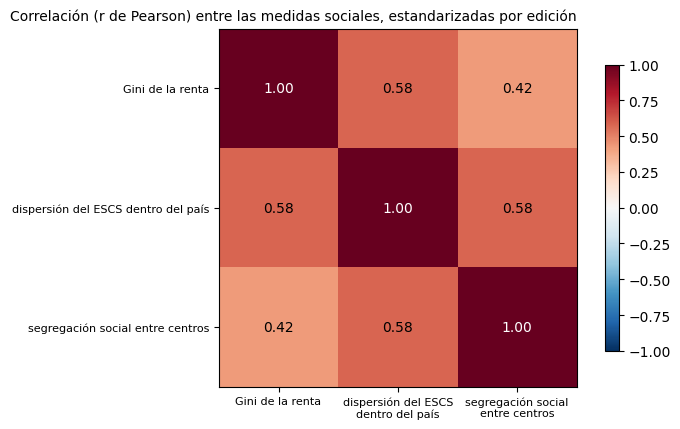

In [6]:
etiquetas = [nombres_variables[variable] for variable in SOCIAL]
correlacion_entre_medidas_sociales = datos_estandarizados[SOCIAL].corr()
fig, ax = plt.subplots(figsize=(7, 4.4))
mapa_calor = ax.imshow(correlacion_entre_medidas_sociales, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(3), [etiqueta.replace(' dentro del', '\ndentro del').replace(' entre', '\nentre') for etiqueta in etiquetas], fontsize=8)
ax.set_yticks(range(3), etiquetas, fontsize=8)
for fila in range(3):
    for columna in range(3):
        ax.text(columna, fila, f'{correlacion_entre_medidas_sociales.iloc[fila, columna]:.2f}', ha='center', va='center', color='white' if abs(correlacion_entre_medidas_sociales.iloc[fila, columna]) > 0.6 else 'black')
fig.colorbar(mapa_calor, ax=ax, shrink=0.8)
ax.set_title('Correlación (r de Pearson) entre las medidas sociales, estandarizadas por edición', fontsize=10, loc='right')
plt.tight_layout()
fig.savefig(f'{RUTA_REPORTS}/01_correlacion_medidas_sociales.png', dpi=300, bbox_inches='tight')
plt.show() 

Las tres medidas correlacionan entre 0,42 (Gini y segregación) y 0,58 (dispersión del `ESCS` con cada una de las otras dos): están relacionadas, pero cada una aporta información propia.

## 4. Desigualdad de recursos entre centros


La **brecha** de cada recurso es la resta de la media del cuartil de centros más desfavorecido con la del más favorecido (según el `ESCS` medio de sus alumnos).


$$ \text{Brecha} = \text{Media}_{\text{Desfavorecido}} - \text{Media}_{\text{Favorecido}} $$


In [7]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 6), sharey=False)
for ax, (columna_brecha, titulo) in zip(ejes, [('pisa_brecha_alumnos_por_profesor', 'alumnos por profesor'), ('pisa_brecha_tamaño_clase', 'tamaño de clase'),
                                     ('pisa_brecha_profesorado_certificado', 'profesorado certificado (pp)')]):
    brecha_2022 = tabla_pais_edicion[tabla_pais_edicion['edicion'] == 2022].dropna(subset=[columna_brecha]).set_index('pais')[columna_brecha].sort_values()
    brecha_2022.plot.barh(ax=ax, color=['tab:green' if valor_brecha < 0 else 'tab:red' for valor_brecha in brecha_2022] if columna_brecha != 'pisa_brecha_profesorado_certificado'
                else ['tab:red' if valor_brecha < 0 else 'tab:green' for valor_brecha in brecha_2022])
    ax.axvline(0, color='black', lw=0.8)
    ax.set_title(titulo, fontsize=10)
    ax.set_ylabel('')
plt.suptitle('Brecha de recursos 2022: centros desfavorecidos menos favorecidos (verde = mejor dotados los desfavorecidos)', fontsize=11)
plt.tight_layout()
fig.savefig(f'{RUTA_REPORTS}/01_brecha_recursos_entre_centros.png', dpi=300, bbox_inches='tight')
plt.close(fig)


Para interpretar los resultados negativos hay que atender al tipo de variable que se está analizando:

* En variables de carga (alumnos por profesor, tamaño de clase o escasez): Un valor negativo es mejor, ya que indica que los centros desfavorecidos tienen menos saturación o menos faltas materiales.
* En variables de calidad (profesorado certificado): Un valor negativo es peor, ya que indica que los centros desfavorecidos cuentan con un menor porcentaje de docentes cualificados.


Para facilitar la lectura, los valores se muestran en términos de equidad: el color <span style="color: #2e7d32; font-weight: bold;">verde</span> indica ventaja para los centros desfavorecidos y el <span style="color: #c62828; font-weight: bold;">rojo</span> indica desventaja.


<img src="../../reports/01_brecha_recursos_entre_centros.png" alt="Brecha de recursos entre centros en 2022" width="70%">

In [8]:
# Patrones de 2022 que se comentan en los hallazgos
brechas_2022 = tabla_pais_edicion[tabla_pais_edicion['edicion'] == 2022].set_index('pais')
for columna, recurso in (('pisa_brecha_alumnos_por_profesor', 'alumnos por profesor'), ('pisa_brecha_tamaño_clase', 'tamaño de clase')):
    valores = brechas_2022[columna].dropna()
    print(f'**{recurso}:\n  -los centros desfavorecidos están mejor dotados (brecha negativa) en {(valores < 0).sum()} de {len(valores)} países;\n  -brecha positiva en: {", ".join(valores[valores > 0].index)}\n')
certificados = brechas_2022['pisa_brecha_profesorado_certificado'].dropna().sort_values()
print('**Profesorado certificado: \n    -brecha en puntos porcentuales (4 menores y 4 mayores):', certificados.head(4).round(0).to_dict(), certificados.tail(4).round(0).to_dict())

**alumnos por profesor:
  -los centros desfavorecidos están mejor dotados (brecha negativa) en 22 de 31 países;
  -brecha positiva en: CHE, CZE, DNK, FRA, GBR, MEX, PRT, TUR, USA

**tamaño de clase:
  -los centros desfavorecidos están mejor dotados (brecha negativa) en 29 de 31 países;
  -brecha positiva en: GBR, POL

**Profesorado certificado: 
    -brecha en puntos porcentuales (4 menores y 4 mayores): {'CAN': -21.0, 'ISR': -20.0, 'NLD': -15.0, 'AUT': -11.0} {'MEX': 20.0, 'USA': 25.0, 'FRA': 27.0, 'TUR': 29.0}


### 4.1 Relación con el rendimiento

In [9]:
etiquetas_vars = {**nombres_variables, 'pisa_brecha_alumnos_por_profesor': 'brecha alumnos por profesor', 'pisa_brecha_tamaño_clase': 'brecha tamaño de clase',
                  'pisa_brecha_profesorado_certificado': 'brecha profesorado certificado', 'pisa_brecha_escasez_material': 'brecha escasez de material (desde 2015)',
                  'pisa_brecha_escasez_personal': 'brecha escasez de personal (desde 2015)'}
correlacion_con_matematicas = pd.DataFrame({variable: {'r': datos_estandarizados[['pisa_matematicas', variable]].dropna().corr().iloc[0, 1], 'n': len(datos_estandarizados[['pisa_matematicas', variable]].dropna())} for variable in vars_equidad}).T
correlacion_con_matematicas = correlacion_con_matematicas.sort_values('r', key=abs)
fig, ax = plt.subplots(figsize=(9, 4.2))
barras = ax.barh([etiquetas_vars[variable] for variable in correlacion_con_matematicas.index], correlacion_con_matematicas['r'],
                 color=['tab:blue' if variable in SOCIAL else 'tab:orange' for variable in correlacion_con_matematicas.index])
ax.bar_label(barras, labels=[f'{correlacion:.2f}  (n={int(n_observaciones)})' for correlacion, n_observaciones in zip(correlacion_con_matematicas['r'], correlacion_con_matematicas['n'])], padding=3, fontsize=8)
ax.axvline(0, color='black', lw=0.8)
ax.set_xlim(-0.9, 0.2)
ax.set_xlabel('correlación (r de Pearson) con PISA matemáticas\n(variables estandarizadas por edición)')
ax.set_title('Desigualdad y rendimiento (azul: social; naranja: recursos entre centros)', fontsize=10)
fig.savefig(f'{RUTA_REPORTS}/01_ranking_correlacion_variables_sociales_recursos.png', dpi=300, bbox_inches='tight')
plt.close(fig)

<img src="../../reports/01_ranking_correlacion_variables_sociales_recursos.png" alt="Correlación de las medidas de desigualdad con la nota de matemáticas" width="80%">

### 4.2 España y estabilidad entre ediciones

Posición de España en 2022 y cuánto se parecen los países entre ediciones, para situar los resultados anteriores.

In [10]:
medidas_espana = ['gini', 'pisa_escs_trend_desviacion_tipica', 'pisa_segregacion_social_entre_centros_pct', 'pisa_brecha_alumnos_por_profesor']
medidas_2022 = tabla_pais_edicion[tabla_pais_edicion['edicion'] == 2022].set_index('pais')[medidas_espana]
display(pd.DataFrame({'España': medidas_2022.loc['ESP'], 'mediana': medidas_2022.median(), 'puesto de mayor a menor': medidas_2022.rank(ascending=False).loc['ESP'].astype(int),
                      'países con dato': medidas_2022.count()}).round(3))

# Estabilidad: correlación entre países de los valores de 2015 y de 2022
estabilidad = pd.Series({variable: tabla_pais_edicion.pivot(index='pais', columns='edicion', values=variable)[[2015, 2022]].dropna().corr().iloc[0, 1] for variable in SOCIAL + RECURSOS},
                        name='correlación entre países 2015-2022')
estabilidad.round(2)

,España,mediana,puesto de mayor a menor,países con dato
gini,0.316,0.309,15,31
pisa_escs_trend_desviacion_tipica,1.009,0.920,5,33
pisa_segregacion_social_entre_centros_pct,23.288,26.106,23,33
pisa_brecha_alumnos_por_profesor,-4.536,-1.247,30,31


gini                                         0.94
pisa_escs_trend_desviacion_tipica            0.88
pisa_segregacion_social_entre_centros_pct    0.85
pisa_brecha_alumnos_por_profesor             0.71
pisa_brecha_tamaño_clase                     0.72
pisa_brecha_profesorado_certificado          0.31
pisa_brecha_escasez_material                 0.68
pisa_brecha_escasez_personal                 0.44
Name: correlación entre países 2015-2022, dtype: float64

## Hallazgos

* **La desigualdad social se asocia con peor rendimiento** (dentro de cada edición, 33 países): dispersión del `ESCS` r = −0,70, Gini −0,59 y segregación entre centros −0,57. Entre sí correlacionan 0,42-0,58: son medidas distintas pero solapadas, no tres pruebas independientes.
* **Las brechas de recursos también**: escasez de material (−0,55; solo desde 2015), alumnos por profesor (−0,47) y escasez de personal (−0,41). Cuanto peor dotados están los centros desfavorecidos respecto a los favorecidos, menos puntos obtiene el país. Tamaño de clase (−0,31) y profesorado certificado (−0,24) son más débiles; en certificados el signo es contrario al esperado (más profesorado certificado en los desfavorecidos, peor media), así que no es concluyente.
* **Los centros desfavorecidos no siempre están peor dotados**: en 2022, en 22 de 31 países tienen menos alumnos por profesor y en 29 de 31 clases más pequeñas; lo contrario ocurre en 9 países en alumnos por profesor (Suiza, Chequia, Dinamarca, Francia, Reino Unido, México, Portugal, Turquía y Estados Unidos) y en 2 en tamaño de clase (Reino Unido y Polonia). Puede reflejar centros rurales pequeños y no solo compensación. En profesorado certificado faltan en los desfavorecidos de Canadá, Israel, Países Bajos y Austria (−11 a −21 puntos porcentuales) y sobran en Turquía, Francia, Estados Unidos y México (+20 a +29).
* **España en 2022**: Gini 0,316 (puesto 15 de 31, cerca de la mediana 0,309), dispersión del `ESCS` 1,01 (puesto 5 de 33: de las más altas), segregación 23,3 % (puesto 23 de 33: por debajo de la mediana, 26,1 %) y brecha de alumnos por profesor de −4,5 (puesto 30 de 31: de los países donde los centros desfavorecidos están mejor dotados).

**Cautelas**: son 33 países y las medidas sociales cambian poco entre ediciones (correlación entre países 2015-2022 de 0,85 a 0,94), así que las 4 ediciones aportan poco más que 33 observaciones independientes; las brechas de recursos son menos estables (0,31 a 0,72); las asociaciones no son causales y mezclan el nivel de renta y de desarrollo del país; las brechas de escasez de material y de personal solo existen desde 2015; el Gini no tiene dato de Australia e Islandia en 2022.

## Otros indicadores del sistema escolar (no analizados)

`construir_tabla` calcula más variables de contexto que **no** se analizan aquí, porque no forman un tema con el de equidad o aportan poco más que las anteriores: tiempo de aprendizaje en clase (`pisa_minutos_semanales_*`), autonomía sobre recursos (`pisa_autonomia_recursos`, sin dato en 2018 y no comparable entre ediciones), recursos de los centros (`pisa_alumnos_por_profesor`, `pisa_tamaño_clase`, `pisa_tamaño_centro`, `pisa_ordenadores_por_alumno`, `pisa_escasez_material_educativo`, `pisa_escasez_personal`), profesorado (`pisa_profesores_certificados_pct`, `pisa_profesores_master_pct`, `docentes_50_o_mas_años_pct`, `docentes_menos_de_30_años_pct`, `horas_docencia_anuales_secundaria_primera_etapa`), acceso y trayectoria (`escolarizacion_*_años_pct`, `repeticion_pct_secundaria_primera_etapa`) y titularidad (`pisa_centros_publicos_pct`). Están disponibles en `tabla_pais_edicion` si hicieran falta.